In [ ]:
# Cell 1: Import libraries and load data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, VotingClassifier, StackingClassifier
from xgboost import XGBClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import accuracy_score, roc_curve, auc
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# Load and explore the data
from google.colab import files
uploaded = files.upload()


# Load data
df = pd.read_csv('alzheimers_disease_data.csv')
print("Original dataset shape:", df.shape)

Saving alzheimers_disease_data.csv to alzheimers_disease_data (1).csv
Original dataset shape: (2149, 35)


In [ ]:
# Cell 2: Data preprocessing
# Label Encoding
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
label_encoders = {}
for col in categorical_cols:
    if col in df.columns:
        le = LabelEncoder()
        df[col] = le.fit_transform(df[col].astype(str))
        label_encoders[col] = le

# Handle missing values
if df.isnull().sum().sum() > 0:
    df = df.fillna(df.mean())

print("After preprocessing shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())

After preprocessing shape: (2149, 35)
Missing values: 0


In [ ]:
# Cell 3: Prepare data for modeling
# Use last column as target if 'Diagnosis' doesn't exist
target_col = 'Diagnosis' if 'Diagnosis' in df.columns else df.columns[-1]
print(f"Target variable: {target_col}")

X = df.drop(columns=[target_col])
y = df[target_col]

print(f"Features shape: {X.shape}")
print(f"Target distribution:\n{y.value_counts()}")

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Training set: {X_train.shape}, Test set: {X_test.shape}")

Target variable: Diagnosis
Features shape: (2149, 34)
Target distribution:
Diagnosis
0    1389
1     760
Name: count, dtype: int64
Training set: (1719, 34), Test set: (430, 34)


In [ ]:
# Cell 4: Feature Selection
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Select top 15 features
selector = SelectKBest(score_func=f_classif, k=15)
X_train_selected = selector.fit_transform(X_train_scaled, y_train)
X_test_selected = selector.transform(X_test_scaled)

# Get selected feature names
selected_mask = selector.get_support()
selected_features = X.columns[selected_mask]
print(f"Selected {len(selected_features)} features:")
print(selected_features.tolist())

# Update training and test sets
X_train_final = pd.DataFrame(X_train_selected, columns=selected_features, index=X_train.index)
X_test_final = pd.DataFrame(X_test_selected, columns=selected_features, index=X_test.index)

Selected 15 features:
['PatientID', 'EducationLevel', 'SleepQuality', 'FamilyHistoryAlzheimers', 'CardiovascularDisease', 'Diabetes', 'SystolicBP', 'CholesterolHDL', 'CholesterolTriglycerides', 'MMSE', 'FunctionalAssessment', 'MemoryComplaints', 'BehavioralProblems', 'ADL', 'PersonalityChanges']


In [ ]:
# Cell 5: Initialize and train base models
models = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'SVM': SVC(random_state=42, probability=True),
    'Random Forest': RandomForestClassifier(random_state=42),
    'XGBoost': XGBClassifier(random_state=42, eval_metric='logloss')
}

print("Base Models Performance:")
print("=" * 50)
base_results = {}

for name, model in models.items():
    # Cross-validation
    cv_scores = cross_val_score(model, x, y, cv=5, scoring='accuracy')

    # Training and testing
    model.fit(X_train_final, y_train)
    y_pred = model.predict(X_test_final)
    test_accuracy = accuracy_score(y_test, y_pred)

    base_results[name] = {
        'model': model,
        'cv_mean': cv_scores.mean(),
        'test_accuracy': test_accuracy
    }

    print(f"{name}:")
    print(f"  CV Accuracy: {cv_scores.mean():.4f} (+/- {cv_scores.std() * 2:.4f})")
    print(f"  Test Accuracy: {test_accuracy:.4f}")
    print("-" * 30)

Base Models Performance:
Logistic Regression:
  CV Accuracy: 0.8429 (+/- 0.0450)
  Test Accuracy: 0.8163
------------------------------
SVM:
  CV Accuracy: 0.8581 (+/- 0.0281)
  Test Accuracy: 0.8698
------------------------------
Random Forest:
  CV Accuracy: 0.9424 (+/- 0.0329)
  Test Accuracy: 0.9558
------------------------------
XGBoost:
  CV Accuracy: 0.9477 (+/- 0.0176)
  Test Accuracy: 0.9581
------------------------------


In [ ]:
# Cell 6: Ensemble Methods
print("\nEnsemble Methods:")
print("=" * 50)

# Prepare estimators
estimators = [(name, model) for name, model in models.items()]

# Hard Voting
voting_hard = VotingClassifier(estimators=estimators, voting='hard')
voting_hard_cv = cross_val_score(voting_hard, X_train_final, y_train, cv=5, scoring='accuracy')
voting_hard.fit(X_train_final, y_train)
voting_hard_test = accuracy_score(y_test, voting_hard.predict(X_test_final))

# Soft Voting
voting_soft = VotingClassifier(estimators=estimators, voting='soft')
voting_soft_cv = cross_val_score(voting_soft, X_train_final, y_train, cv=5, scoring='accuracy')
voting_soft.fit(X_train_final, y_train)
voting_soft_test = accuracy_score(y_test, voting_soft.predict(X_test_final))

# Stacking
stacking_clf = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegression(random_state=42, max_iter=1000)
)
stacking_cv = cross_val_score(stacking_clf, X_train_final, y_train, cv=5, scoring='accuracy')
stacking_clf.fit(X_train_final, y_train)
stacking_test = accuracy_score(y_test, stacking_clf.predict(X_test_final))

# Print results
ensemble_results = {
    'Hard Voting': {'cv': voting_hard_cv.mean(), 'test': voting_hard_test},
    'Soft Voting': {'cv': voting_soft_cv.mean(), 'test': voting_soft_test},
    'Stacking': {'cv': stacking_cv.mean(), 'test': stacking_test}
}

for name, results in ensemble_results.items():
    print(f"{name}:")
    print(f"  CV Accuracy: {results['cv']:.4f}")
    print(f"  Test Accuracy: {results['test']:.4f}")
    print("-" * 30)


Ensemble Methods:
Hard Voting:
  CV Accuracy: 0.9046
  Test Accuracy: 0.9140
------------------------------
Soft Voting:
  CV Accuracy: 0.9407
  Test Accuracy: 0.9395
------------------------------
Stacking:
  CV Accuracy: 0.9471
  Test Accuracy: 0.9605
------------------------------


In [ ]:
# Cell 7: Hyperparameter Tuning
print("Hyperparameter Tuning:")
print("=" * 50)

param_grids = {
    'Logistic Regression': {
        'C': [0.1, 1, 10],
        'penalty': ['l2'],
        'solver': ['liblinear']
    },
    'SVM': {
        'C': [0.1, 1, 10],
        'kernel': ['linear', 'rbf']
    },
    'Random Forest': {
        'n_estimators': [50, 100],
        'max_depth': [10, 20]
    },
    'XGBoost': {
        'n_estimators': [50, 100],
        'max_depth': [3, 6],
        'learning_rate': [0.1, 0.2]
    }
}

best_models = {}
for name, model in models.items():
    print(f"Tuning {name}...")
    grid_search = GridSearchCV(
        model, param_grids[name], cv=3, scoring='accuracy', n_jobs=-1, verbose=0
    )
    grid_search.fit(X_train_final, y_train)
    best_models[name] = grid_search.best_estimator_
    print(f"  Best score: {grid_search.best_score_:.4f}")
    print(f"  Best params: {grid_search.best_params_}")

Hyperparameter Tuning:
Tuning Logistic Regression...
  Best score: 0.8447
  Best params: {'C': 0.1, 'penalty': 'l2', 'solver': 'liblinear'}
Tuning SVM...
  Best score: 0.8557
  Best params: {'C': 1, 'kernel': 'rbf'}
Tuning Random Forest...
  Best score: 0.9401
  Best params: {'max_depth': 10, 'n_estimators': 100}
Tuning XGBoost...
  Best score: 0.9506
  Best params: {'learning_rate': 0.2, 'max_depth': 3, 'n_estimators': 50}


In [ ]:
# Cell 8: Evaluate tuned models and ensembles
print("\nTuned Models & Ensembles:")
print("=" * 50)

# Evaluate tuned models
tuned_results = {}
for name, model in best_models.items():
    cv_scores = cross_val_score(model, X_train_final, y_train, cv=5, scoring='accuracy')
    y_pred = model.predict(X_test_final)
    test_accuracy = accuracy_score(y_test, y_pred)
    tuned_results[name] = test_accuracy
    print(f"{name}: CV={cv_scores.mean():.4f}, Test={test_accuracy:.4f}")

# Tuned ensembles
tuned_estimators = [(name, model) for name, model in best_models.items()]

voting_hard_tuned = VotingClassifier(estimators=tuned_estimators, voting='hard')
voting_soft_tuned = VotingClassifier(estimators=tuned_estimators, voting='soft')
stacking_tuned = StackingClassifier(estimators=tuned_estimators,
                                 final_estimator=LogisticRegression())

ensemble_names = ['Hard Voting Tuned', 'Soft Voting Tuned', 'Stacking Tuned']
ensemble_models = [voting_hard_tuned, voting_soft_tuned, stacking_tuned]

for name, model in zip(ensemble_names, ensemble_models):
    cv_scores = cross_val_score(model, X_train_final, y_train, cv=5, scoring='accuracy')
    model.fit(X_train_final, y_train)
    test_acc = accuracy_score(y_test, model.predict(X_test_final))
    print(f"{name}: CV={cv_scores.mean():.4f}, Test={test_acc:.4f}")


Tuned Models & Ensembles:
Logistic Regression: CV=0.8435, Test=0.8116
SVM: CV=0.8581, Test=0.8698
Random Forest: CV=0.9424, Test=0.9512
XGBoost: CV=0.9500, Test=0.9581
Hard Voting Tuned: CV=0.9046, Test=0.9116
Soft Voting Tuned: CV=0.9343, Test=0.9372
Stacking Tuned: CV=0.9506, Test=0.9488


ROC Curves:


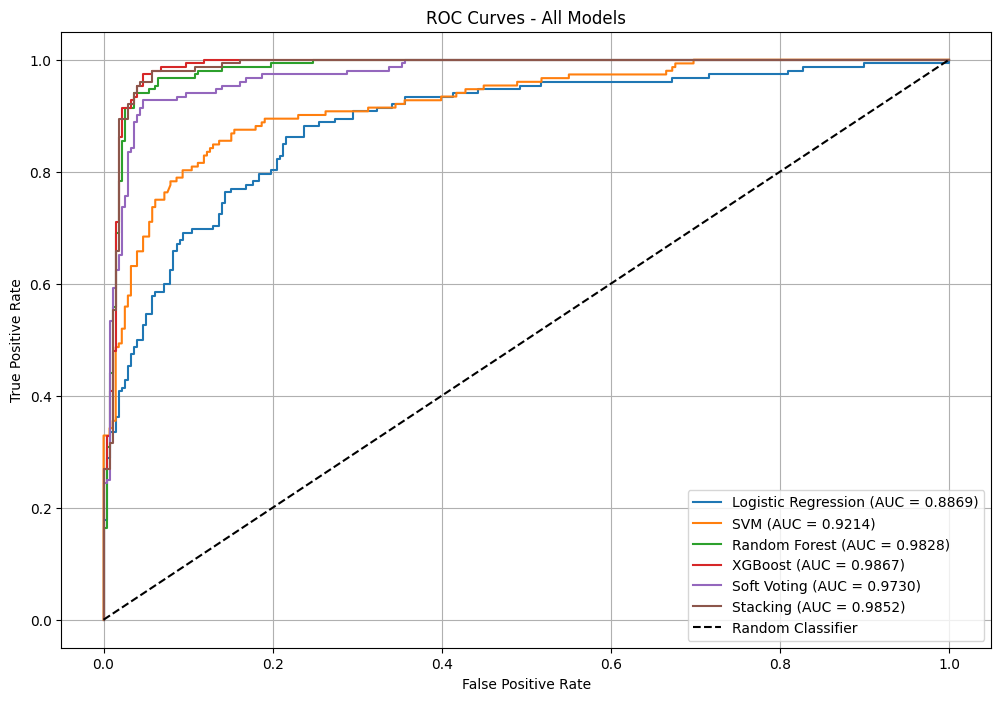

In [ ]:
# Cell 9: ROC Curves
print("ROC Curves:")
print("=" * 50)

plt.figure(figsize=(12, 8))

# Combine all models
all_models = {}
all_models.update(best_models)
all_models['Hard Voting'] = voting_hard_tuned
all_models['Soft Voting'] = voting_soft_tuned
all_models['Stacking'] = stacking_tuned

# Plot ROC curves
for name, model in all_models.items():
    if hasattr(model, 'predict_proba'):
        y_proba = model.predict_proba(X_test_final)[:, 1]
        fpr, tpr, _ = roc_curve(y_test, y_proba)
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.4f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves - All Models')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Cell 10: Final Summary
print("FINAL SUMMARY")
print("=" * 50)

print("\nBest Individual Models:")
for name, acc in tuned_results.items():
    print(f"{name}: {acc:.4f}")

print("\nBest Ensemble Methods:")
ensemble_accuracies = {
    'Hard Voting': voting_hard_test,
    'Soft Voting': voting_soft_test,
    'Stacking': stacking_test
}
for name, acc in ensemble_accuracies.items():
    print(f"{name}: {acc:.4f}")

best_model = max(tuned_results.items(), key=lambda x: x[1])
print(f"\nBest Model: {best_model[0]} with accuracy {best_model[1]:.4f}")

FINAL SUMMARY

Best Individual Models:
Logistic Regression: 0.8116
SVM: 0.8698
Random Forest: 0.9512
XGBoost: 0.9581

Best Ensemble Methods:
Hard Voting: 0.9140
Soft Voting: 0.9395
Stacking: 0.9605

Best Model: XGBoost with accuracy 0.9581
